In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

# FR : Fixer la graine pour rendre les expériences plus reproductibles.
# EN: Set a random seed to make experiments more reproducible.
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# FR : Keras fournit Fashion-MNIST avec un ensemble train initial et un ensemble test.
# EN: Keras provides Fashion-MNIST with an initial training set and a separate test set.
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Original training images:", X_train_full.shape)
print("Test images:", X_test.shape)
print("Original pixel range:", X_train_full.min(), "to", X_train_full.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Original pixel range: 0 to 255


In [3]:
# FR : Convertir les pixels de 0–255 vers 0–1.
# EN: Convert pixel intensities from 0–255 to 0–1.
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# FR : Transformer chaque image 28×28 en vecteur de 784 valeurs.
# EN: Flatten each 28×28 image into a vector of 784 features.
X_train_full = X_train_full.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Prepared training shape:", X_train_full.shape)
print("Prepared test shape:", X_test.shape)
print("Normalized pixel range:", X_train_full.min(), "to", X_train_full.max())

Prepared training shape: (60000, 784)
Prepared test shape: (10000, 784)
Normalized pixel range: 0.0 to 1.0


In [4]:
# FR : Réserver 20 % des 60 000 images initiales pour la validation.
# EN: Reserve 20% of the original 60,000 images for validation.
# FR : stratify conserve les proportions des 10 classes.
# EN: stratify preserves the proportions of the 10 classes.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=42
)

print("TRAIN:", X_train.shape, y_train.shape)
print("VALIDATION:", X_val.shape, y_val.shape)
print("TEST:", X_test.shape, y_test.shape)
assert X_train.shape == (48000, 784)
assert X_val.shape == (12000, 784)
assert X_test.shape == (10000, 784)

TRAIN: (48000, 784) (48000,)
VALIDATION: (12000, 784) (12000,)
TEST: (10000, 784) (10000,)


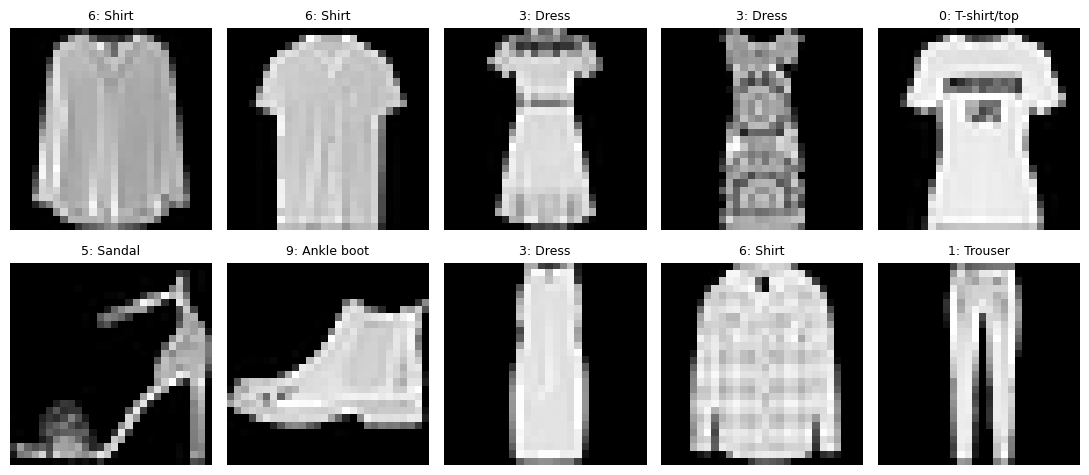

In [5]:
# FR : Les noms correspondent aux étiquettes officielles de Fashion-MNIST.
# EN: Class names correspond to the official Fashion-MNIST labels.
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    # FR : Reconstituer la grille 28×28 uniquement pour l'affichage.
    # EN: Restore the 28×28 grid for display only.
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"{y_train[i]}: {class_names[y_train[i]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# FR : Construire le modèle de référence (baseline).
# EN: Build the baseline model.
baseline_model = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
], name="baseline_32_relu_adam")

# FR : Afficher les couches et le nombre de paramètres.
# EN: Display layers and the number of parameters.
baseline_model.summary()

Model: "baseline_32_relu_adam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# FR : Configurer l'apprentissage du modèle.
# EN: Configure model training.
baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
# FR : Entraîner pendant 10 epochs avec un batch size de 64.
# EN: Train for 10 epochs with a batch size of 64.
history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7907 - loss: 0.6260 - val_accuracy: 0.8356 - val_loss: 0.4745
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8431 - loss: 0.4490 - val_accuracy: 0.8475 - val_loss: 0.4307
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8572 - loss: 0.4095 - val_accuracy: 0.8564 - val_loss: 0.4068
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8662 - loss: 0.3837 - val_accuracy: 0.8608 - val_loss: 0.3924
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8717 - loss: 0.3662 - val_accuracy: 0.8658 - val_loss: 0.3830
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8755 - loss: 0.3530 - val_accuracy: 0.8695 - val_loss: 0.3766
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8796 - loss: 0.3422 - val_accuracy: 0.8704 - val_loss: 0.3703
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8827 - loss: 0.3329 - val_accuracy: 0.

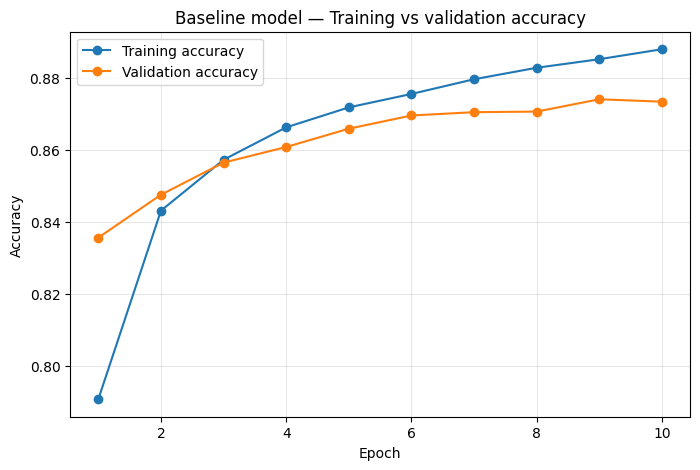

In [9]:
# FR : Visualiser l'évolution des accuracies au cours de l'entraînement.
# EN: Visualize how accuracy changes during training.
epochs_range = range(1, len(history_baseline.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history_baseline.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history_baseline.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline model — Training vs validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
# FR : Créer un modèle neuf avec les réglages choisis.
# EN: Create a fresh model with the selected settings.
def build_model(hidden_neurons=32, hidden_activation="relu", optimizer="adam"):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(784,)),
        tf.keras.layers.Dense(hidden_neurons, activation=hidden_activation),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    # FR : Même loss et même métrique pour toutes les expériences.
    # EN: Same loss and metric for every experiment.
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [11]:
# FR : Expérience 1 : modifier uniquement le nombre de neurones.
# EN: Experiment 1: change only the number of hidden neurons.
model_exp1 = build_model(hidden_neurons=64, hidden_activation="relu", optimizer="adam")
model_exp1.summary()

history_exp1 = model_exp1.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8015 - loss: 0.5765 - val_accuracy: 0.8409 - val_loss: 0.4574
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8533 - loss: 0.4215 - val_accuracy: 0.8583 - val_loss: 0.4058
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8649 - loss: 0.3825 - val_accuracy: 0.8707 - val_loss: 0.3686
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8734 - loss: 0.3572 - val_accuracy: 0.8769 - val_loss: 0.3531
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8775 - loss: 0.3383 - val_accuracy: 0.8789 - val_loss: 0.3453
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8836 - loss: 0.3227 - val_accuracy: 0.8812 - val_loss: 0.3401
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8881 - loss: 0.3097 - val_accuracy: 0.8834 - val_loss: 0.3354
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8920 - loss: 0.2981 - val_accuracy: 0.

In [12]:
# FR : Expérience 2 : modifier uniquement la fonction d'activation cachée.
# EN: Experiment 2: change only the hidden activation function.
model_exp2 = build_model(hidden_neurons=32, hidden_activation="tanh", optimizer="adam")
model_exp2.summary()

history_exp2 = model_exp2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7952 - loss: 0.6019 - val_accuracy: 0.8382 - val_loss: 0.4539
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8494 - loss: 0.4236 - val_accuracy: 0.8533 - val_loss: 0.4066
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8619 - loss: 0.3855 - val_accuracy: 0.8627 - val_loss: 0.3813
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8693 - loss: 0.3626 - val_accuracy: 0.8683 - val_loss: 0.3653
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8751 - loss: 0.3457 - val_accuracy: 0.8709 - val_loss: 0.3560
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8799 - loss: 0.3321 - val_accuracy: 0.8734 - val_loss: 0.3502
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8834 - loss: 0.3209 - val_accuracy: 0.8741 - val_loss: 0.3459
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8861 - loss: 0.3114 - val_accuracy: 0.

In [13]:
# FR : Expérience 3 : modifier uniquement l'optimiseur.
# EN: Experiment 3: change only the optimizer.
model_exp3 = build_model(hidden_neurons=32, hidden_activation="relu", optimizer="sgd")
model_exp3.summary()

history_exp3 = model_exp3.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6839 - loss: 1.0281 - val_accuracy: 0.7719 - val_loss: 0.6977
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7912 - loss: 0.6344 - val_accuracy: 0.8009 - val_loss: 0.5897
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8114 - loss: 0.5640 - val_accuracy: 0.8141 - val_loss: 0.5428
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8214 - loss: 0.5277 - val_accuracy: 0.8232 - val_loss: 0.5151
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8276 - loss: 0.5046 - val_accuracy: 0.8279 - val_loss: 0.4958
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8322 - loss: 0.4880 - val_accuracy: 0.8307 - val_loss: 0.4821
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8365 - loss: 0.4752 - val_accuracy: 0.8355 - val_loss: 0.4715
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8404 - loss: 0.4649 - val_accuracy: 0.

In [14]:
# FR : Construire le tableau comparatif à partir des historiques d'entraînement.
# EN: Build a comparison table from the training histories.
histories = {
    "Baseline (32, ReLU, Adam)": history_baseline,
    "Experiment 1 (64, ReLU, Adam)": history_exp1,
    "Experiment 2 (32, tanh, Adam)": history_exp2,
    "Experiment 3 (32, ReLU, SGD)": history_exp3,
}

results_df = pd.DataFrame([
    {
        "Model": name,
        "Training accuracy": history.history["accuracy"][-1],
        "Validation accuracy": history.history["val_accuracy"][-1],
    }
    for name, history in histories.items()
])

# FR : Afficher les scores en pourcentage pour une lecture plus simple.
# EN: Display scores as percentages for easier reading.
display(results_df.style.format({
    "Training accuracy": "{:.2%}",
    "Validation accuracy": "{:.2%}"
}))

,Model,Training accuracy,Validation accuracy
0,"Baseline (32, ReLU, Adam)",88.79%,87.33%
1,"Experiment 1 (64, ReLU, Adam)",89.73%,88.23%
2,"Experiment 2 (32, tanh, Adam)",89.25%,87.77%
3,"Experiment 3 (32, ReLU, SGD)",84.55%,84.47%


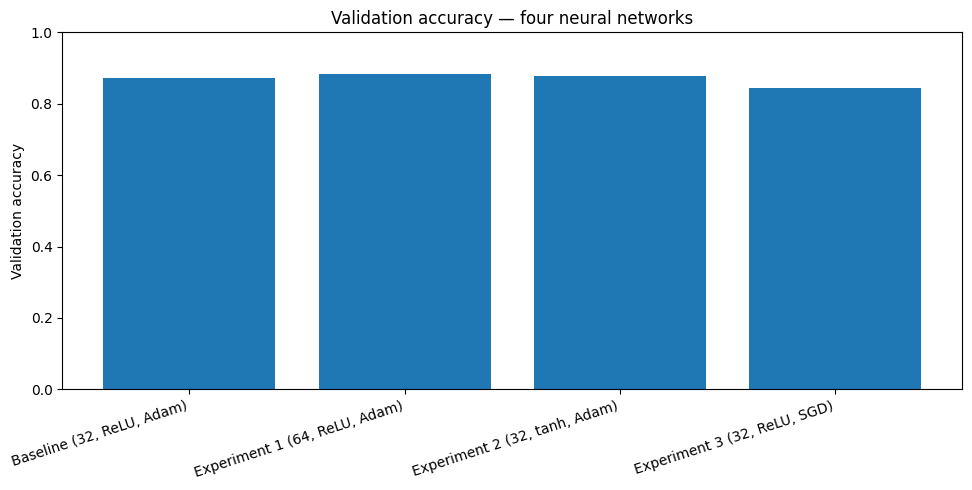

In [15]:
# FR : Comparer les quatre modèles sur VALIDATION (pas sur TEST).
# EN: Compare the four models on VALIDATION (not TEST).
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Validation accuracy"])
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy — four neural networks")
plt.xticks(rotation=18, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [16]:
# FR : Sélectionner le modèle avec la meilleure validation accuracy.
# EN: Select the model with the highest validation accuracy.

best_model = model_exp1

# FR : Évaluer le modèle sélectionné sur les données de test.
# EN: Evaluate the selected model on the test dataset.

test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Selected model: Experiment 1 (64, ReLU, Adam)")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Selected model: Experiment 1 (64, ReLU, Adam)
Test loss: 0.3662
Test accuracy: 86.77%


In [17]:
# FR : Faire des prédictions sur les images de test.
# EN: Make predictions on the test images.

y_prob = best_model.predict(X_test, verbose=0)

# FR : Choisir la catégorie avec la probabilité la plus élevée.
# EN: Select the class with the highest probability.

y_pred = np.argmax(y_prob, axis=1)

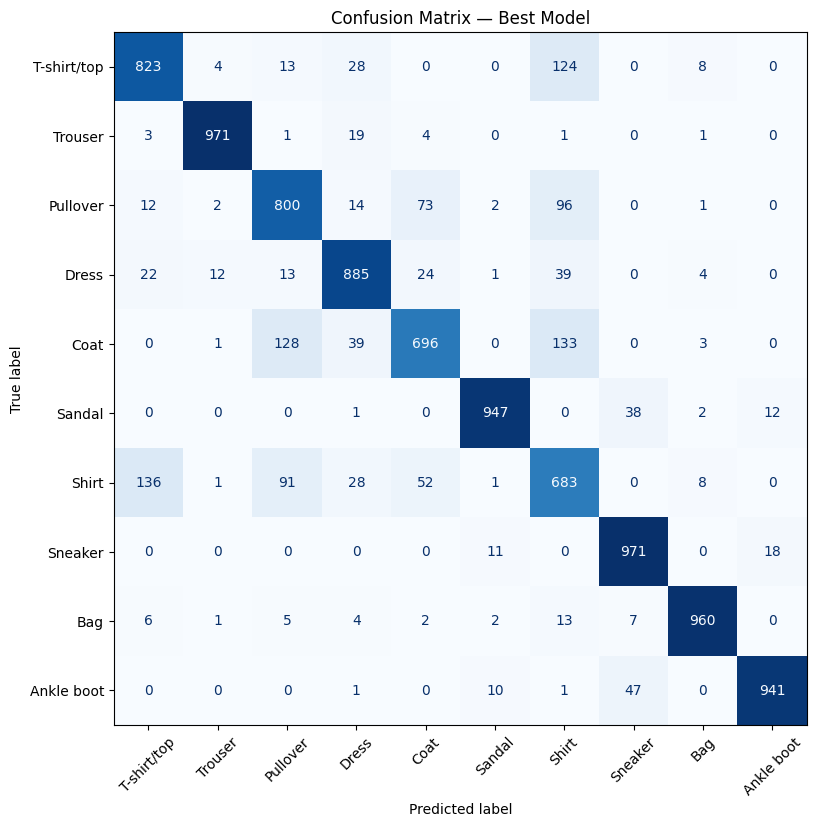

In [18]:
# FR : Importer la fonction pour créer la matrice de confusion.
# EN: Import the function to create the confusion matrix.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# FR : Noms des 10 catégories de vêtements.
# EN: Names of the 10 clothing categories.

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# FR : Comparer les vraies catégories avec les prédictions.
# EN: Compare the true labels with the predicted labels.

cm = confusion_matrix(y_test, y_pred)

# FR : Afficher la matrice de confusion.
# EN: Display the confusion matrix.

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)

plt.title("Confusion Matrix — Best Model")
plt.show()

In [19]:
# FR : Copier la matrice et supprimer les bonnes prédictions.
# EN: Copy the matrix and remove correct predictions.

cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# FR : Trouver la confusion la plus fréquente.
# EN: Find the most frequent misclassification.

true_idx, pred_idx = np.unravel_index(
    np.argmax(cm_errors),
    cm_errors.shape
)

print("True category:", class_names[true_idx])
print("Predicted category:", class_names[pred_idx])
print("Number of errors:", cm_errors[true_idx, pred_idx])

True category: Shirt
Predicted category: T-shirt/top
Number of errors: 136
